In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("housing_price.csv")

In [3]:
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
data.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
Y = np.array(data["price"])

In [7]:
Y.shape

(545,)

In [8]:
X = np.array(data["area"])

In [9]:
X.shape


(545,)

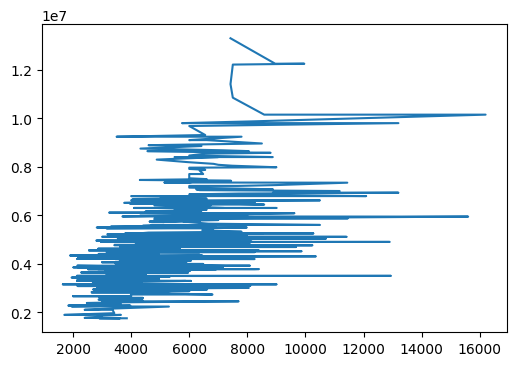

In [10]:
plt.figure(figsize = (6,4))
plt.plot(X, Y)
plt.show()

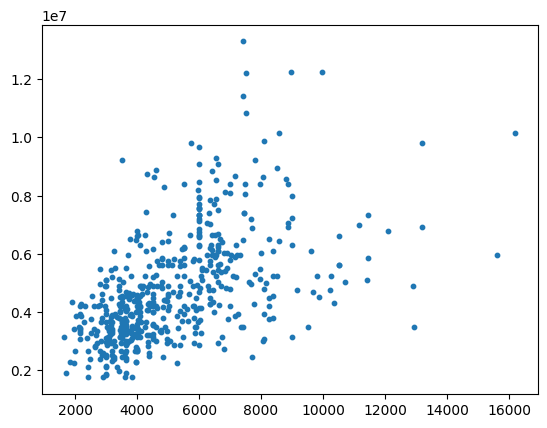

In [11]:
plt.scatter(X, Y,s=10)
plt.show()

In [12]:
def compute_cost(x,y,w,b):
    m = x.shape[0]
    cost = 0
    for i in range(m):
        fx = w*x[i] + b
        cost = cost + (( fx - y[i]) ** 2)
    return cost/2*m


In [13]:
def compute_gradient(x,y,w,b):
    m = x.shape[0]
    df_dw = 0
    df_db = 0
    for i in range(m):
        fx = w*x[i] + b
        gradient_dw = ((fx -y[i]) * x[i])
        gradient_db = (fx -y[i])
        df_dw = df_dw + gradient_dw
        df_db = df_db + gradient_db
    return df_dw / m , df_db / m


In [14]:
def gradient_decent(x,y,learning_rate,num_iterations,initial_w,initial_b):
    w = initial_w
    b = initial_b
    costs = []
    for i in range(num_iterations):
        df_dw,df_db = compute_gradient(x,y,w,b)
        w = w - learning_rate * df_dw
        b = b - learning_rate * df_db
        cost = compute_cost(x,y,w,b)
        costs.append(cost)
    return costs,w,b


In [15]:
iter = 100
learning_rate = 1e-8
initial_w = 100000000
initial_b = 100000000
costs,w,b = gradient_decent(X,Y,learning_rate,iter,initial_w,initial_b)
print(f"Cost after iteration {iter} is {costs[-1]}")


Cost after iteration 100 is 2.1330589596179454e+20


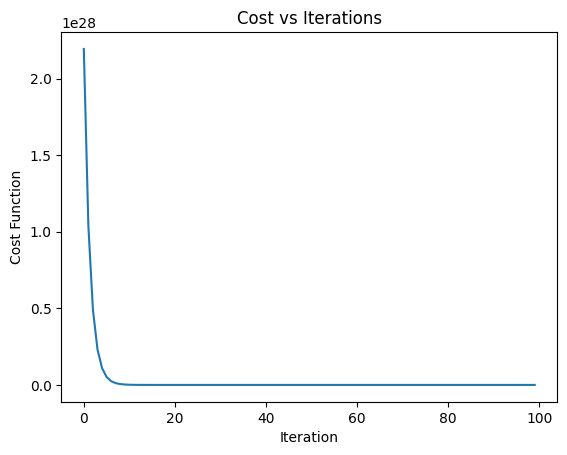

In [16]:
plt.plot(np.arange(iter),costs)
plt.title("Cost vs Iterations")
plt.ylabel("Cost Function")
plt.xlabel("Iteration")
plt.show()

In [17]:
def scale_feature(x):
    _max = np.max(x, axis=0)
    _min = np.min(x, axis=0)
    x_scaled = np.array([])
    for i in range(x.shape[0]):
        x_scaled = np.append(x_scaled, x[i]/_max)
    return x_scaled


In [18]:
X_scaled = scale_feature(X)

In [19]:
X_scaled.shape

(545,)

In [20]:
iter = 100000
learning_rate = 0.01
initial_w = 1
initial_b = 1
costs,w,b = gradient_decent(X_scaled,Y,learning_rate,iter,initial_w,initial_b)
print(f"Cost after iteration {iter} is {costs[-1]}")

Cost after iteration 100000 is 3.6962702839730643e+17


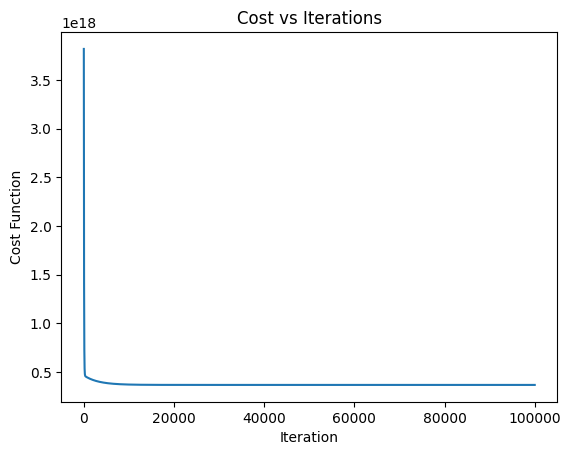

In [21]:
plt.plot(np.arange(iter),costs)
plt.title("Cost vs Iterations")
plt.ylabel("Cost Function")
plt.xlabel("Iteration")
plt.show()

# Multiple regression

In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [23]:
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [41]:
X = np.array(data[["area","bedrooms"]])

In [42]:
X.shape

(545, 2)

In [56]:
Y = np.array(data["price"])

In [57]:
def compute_multi_cost(X,Y,w,b):
    y_pred = np.dot(X,w) + b
    diff = (y_pred - Y)**2
    cost = np.sum(diff)
    return cost / (2 * X.shape[0])

In [58]:
compute_multi_cost(X,Y,[1,1],1)

np.float64(13080189674000.312)

In [72]:
def compute_multi_gradient(X,Y,w,b):
    m = X.shape[0]
    y_pred = np.dot(X,w) + b
    gradient_w = np.dot(((y_pred - Y).reshape(1,m)) ,X)
    gradient_b = np.sum(y_pred - Y)
    return gradient_w/m, gradient_b/m



In [73]:
res = compute_multi_gradient(X,Y,[1,1],1)

In [74]:
res[0]

array([[-2.66916704e+10, -1.46234991e+07]])